### **5. To write and execute a program for histogram calculation and equalization:**

a. Using inbuilt function

b. Without using inbuilt function

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

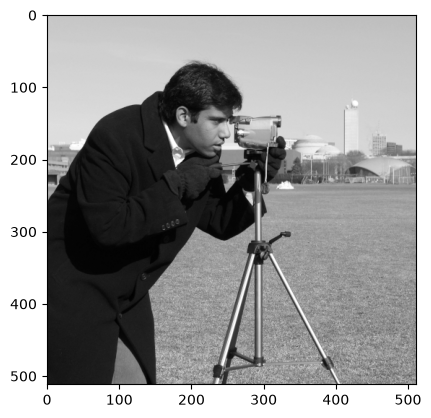

In [2]:
 # Load Image (Low contrast version for demonstration)
img = data.camera()
# Make it lower contrast artificially to see equalization effect better
img_low_contrast = (img * 0.5 + 50).astype(np.uint8)
plt.imshow(img_low_contrast, cmap='gray')

Histogram Equalization using Inbuilt function

C:\Users\SAKSHAM RAJ\AppData\Local\Temp\ipykernel_7464\899393709.py:1: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(img_low_contrast.flatten(), 256, [0,256], color='r')


Text(0, 0.5, 'Frequency')

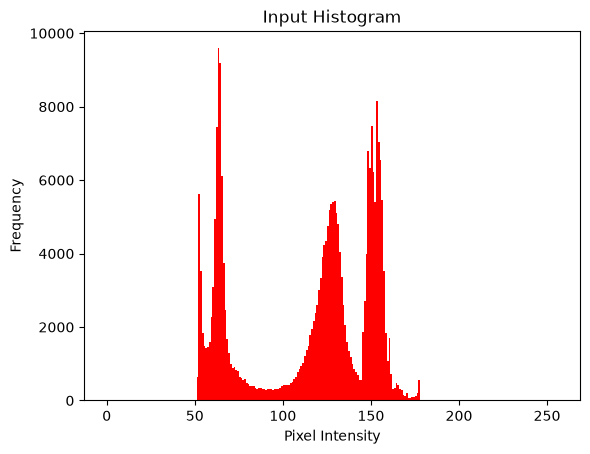

In [3]:
plt.hist(img_low_contrast.flatten(), 256, [0,256], color='r')
plt.title("Input Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

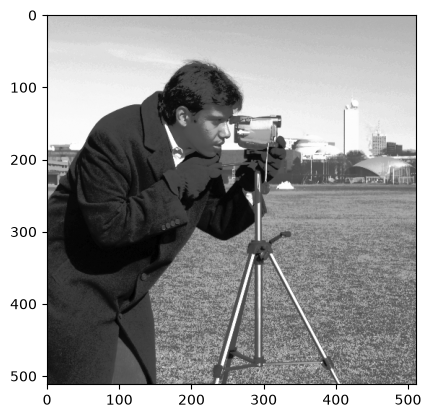

In [4]:
img_eq_inbuilt = cv2.equalizeHist(img_low_contrast)
plt.imshow(img_eq_inbuilt, cmap='gray')

C:\Users\SAKSHAM RAJ\AppData\Local\Temp\ipykernel_7464\2542388932.py:1: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(img_eq_inbuilt.flatten(), 256, [0,256], color='g')


Text(0, 0.5, 'Frequency')

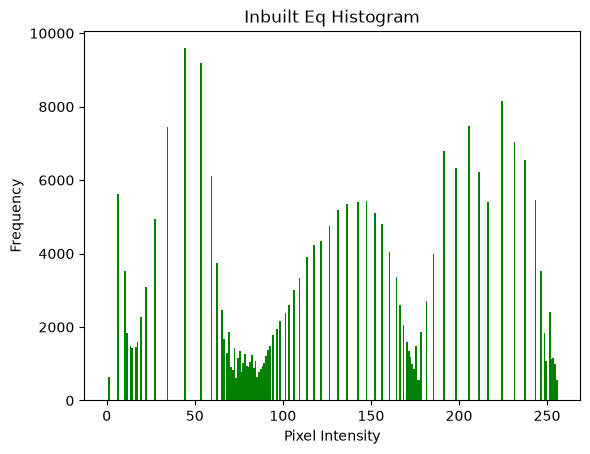

In [5]:
plt.hist(img_eq_inbuilt.flatten(), 256, [0,256], color='g')
plt.title("Inbuilt Eq Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

Histogram Equalization WITHOUT Inbuilt function (Manual)

In [6]:
# 1. Calculate Histogram
hist, bins = np.histogram(img_low_contrast.flatten(), 256, [0,256])
# 2. Calculate CDF (Cumulative Distribution Function)
cdf = hist.cumsum()
# 3. Normalize CDF
cdf_normalized = cdf * hist.max() / cdf.max() # For visualization only
# 4. Mask masked arrays to avoid division by zero (if any)
cdf_m = np.ma.masked_equal(cdf, 0)
# 5. Equalization formula: h(v) = round((cdf(v) - cdfmin) / (MxN - 1) * (L-1))
cdf_m = (cdf_m - cdf_m.min())*255/(cdf_m.max()-cdf_m.min())
cdf_final = np.ma.filled(cdf_m, 0).astype('uint8')
# 6. Map original pixels to new values
img_eq_manual = cdf_final[img_low_contrast]
    

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

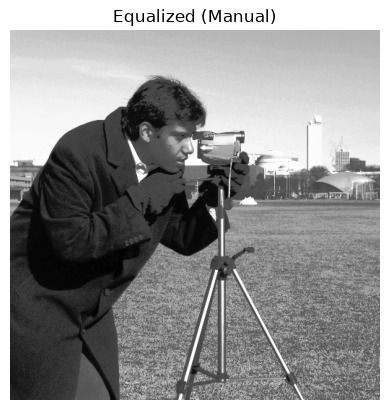

In [7]:
plt.imshow(img_eq_manual, cmap='gray')
plt.title("Equalized (Manual)")
plt.axis('off')

C:\Users\SAKSHAM RAJ\AppData\Local\Temp\ipykernel_7464\900940627.py:1: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(img_eq_manual.flatten(), 256, [0,256], color='b')


Text(0, 0.5, 'Frequency')

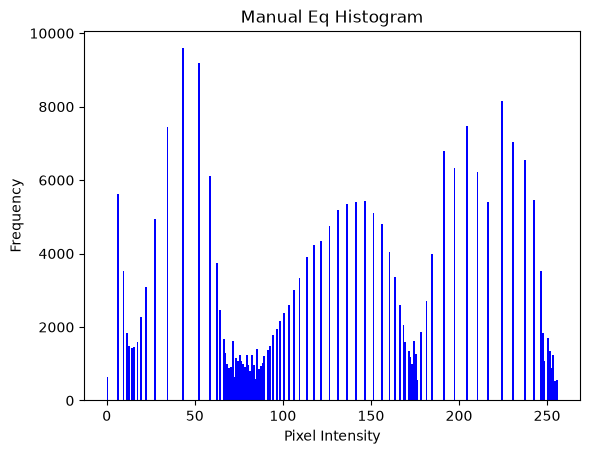

In [8]:
plt.hist(img_eq_manual.flatten(), 256, [0,256], color='b')
plt.title("Manual Eq Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")